In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

ROOT = Path(".") if Path("data").exists() else Path("..")
OUT_DIR = ROOT / "data/processed"

DELHI_LAT, DELHI_LON = 28.53, 77.19
START, END = "2025-03-01", "2025-11-30"
ALL_DATES = pd.date_range(START, END, name="date")
MONTH_ORDER = ["Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]

fires = pd.read_csv(OUT_DIR / "fires_clean.csv", parse_dates=["time_ist", "date"])
fires["month_name"] = fires["date"].dt.strftime("%b")

In [3]:
monthly = fires.groupby("month_name").agg(
    detections=("frp", "size"),
    total_frp_MW=("frp", "sum"),
    mean_frp_MW=("frp", "mean"),
).reindex(MONTH_ORDER).round(1)
monthly

,detections,total_frp_MW,mean_frp_MW
month_name,,,
Mar,1046,3764.4,3.6
Apr,4303,30181.1,7.0
May,13481,83430.6,6.2
Jun,731,3494.8,4.8
Jul,59,281.7,4.8
Aug,33,142.1,4.3
Sep,206,692.0,3.4
Oct,1877,8875.5,4.7
Nov,4429,23032.7,5.2


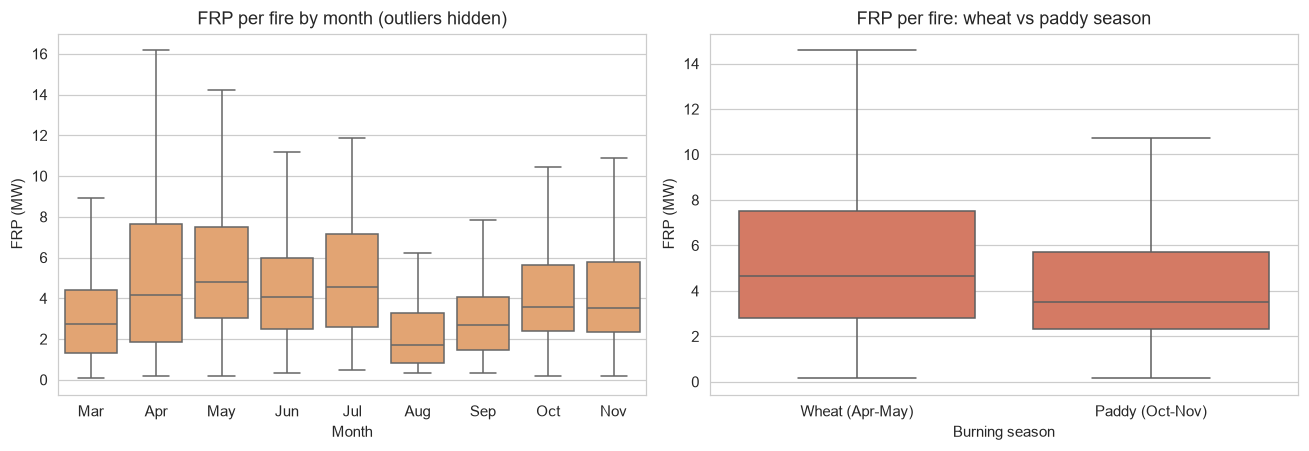

,count,median,mean
season,,,
Paddy (Oct-Nov),6306,3.52,5.06
Wheat (Apr-May),17784,4.67,6.39


In [4]:
fires["season"] = np.select(
    [fires["month"].isin([4, 5]), fires["month"].isin([10, 11])],
    ["Wheat (Apr-May)", "Paddy (Oct-Nov)"],
    default="Other",
)
crop_seasons = fires[fires["season"] != "Other"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=fires, x="month_name", y="frp", order=MONTH_ORDER, showfliers=False,
            color="#f4a261", ax=axes[0])
axes[0].set_title("FRP per fire by month (outliers hidden)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("FRP (MW)")

sns.boxplot(data=crop_seasons, x="season", y="frp", showfliers=False,
            color="#e76f51", ax=axes[1])
axes[1].set_title("FRP per fire: wheat vs paddy season")
axes[1].set_xlabel("Burning season")
axes[1].set_ylabel("FRP (MW)")
fig.tight_layout()
plt.show()

crop_seasons.groupby("season")["frp"].agg(["count", "median", "mean"]).round(2)

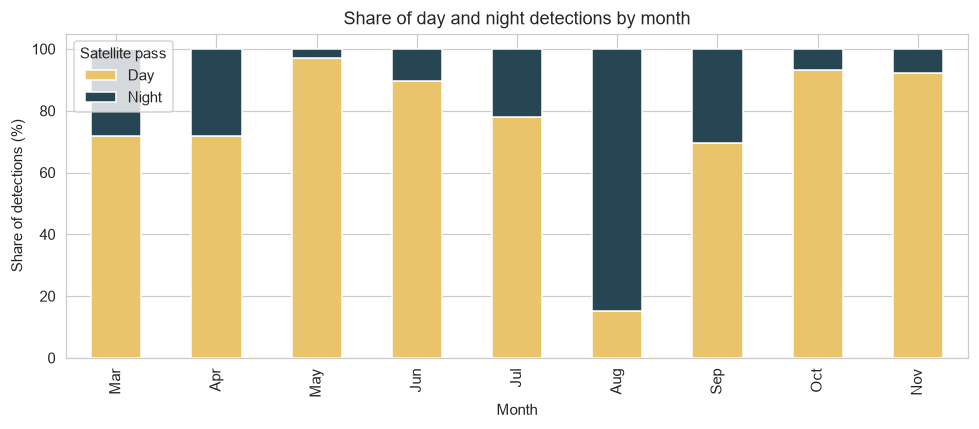

In [5]:
day_night = (pd.crosstab(fires["month_name"], fires["daynight"], normalize="index")
             .mul(100)
             .reindex(MONTH_ORDER)
             .rename(columns={"D": "Day", "N": "Night"}))

ax = day_night.plot(kind="bar", stacked=True, figsize=(9, 4),
                    color={"Day": "#e9c46a", "Night": "#264653"})
ax.set_title("Share of day and night detections by month")
ax.set_xlabel("Month")
ax.set_ylabel("Share of detections (%)")
ax.legend(title="Satellite pass")
plt.tight_layout()
plt.show()

In [6]:
import plotly.express as px

month_frames = fires.assign(month_label=fires["date"].dt.strftime("%m %b")).sort_values("date")

fig = px.scatter_geo(
    month_frames, lat="latitude", lon="longitude", color="frp",
    animation_frame="month_label", color_continuous_scale="YlOrRd",
    range_color=(0, 30), opacity=0.6,
    labels={"frp": "FRP (MW)", "month_label": "Month"},
    title="Fire detections by month (colour = FRP)",
)
fig.add_scattergeo(lat=[DELHI_LAT], lon=[DELHI_LON], mode="markers+text", text=["Delhi"],
                   textposition="top center", marker=dict(size=13, color="blue", symbol="star"),
                   showlegend=False)
fig.update_geos(lataxis_range=[26.5, 31.5], lonaxis_range=[73.5, 79.5],
                showcountries=True, showsubunits=True)
fig.update_layout(height=550)
fig.show()

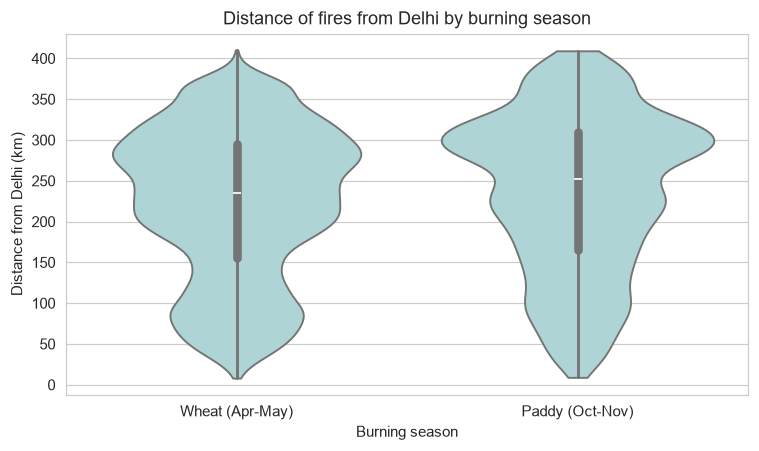

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.violinplot(data=crop_seasons, x="season", y="dist_km", color="#a8dadc", cut=0, ax=ax)
ax.set_title("Distance of fires from Delhi by burning season")
ax.set_xlabel("Burning season")
ax.set_ylabel("Distance from Delhi (km)")
fig.tight_layout()
plt.show()

In [8]:
fires["dist_band"] = pd.cut(fires["dist_km"], bins=[0, 150, 300, 450], labels=["<150 km", "150-300 km", ">300 km"])
band_share = pd.crosstab(fires["season"], fires["dist_band"], normalize="index").mul(100).round(1)
band_share.loc[["Wheat (Apr-May)", "Paddy (Oct-Nov)"]]

dist_band,<150 km,150-300 km,>300 km
season,,,
Wheat (Apr-May),24.0,53.3,22.7
Paddy (Oct-Nov),21.7,48.2,30.1


In [9]:
fires["region"] = np.select(
    [(fires["latitude"] >= 29.5) & (fires["longitude"] < 76.5), fires["latitude"] < 28.2],
    ["north-west", "south"],
    default="central",
)
pd.crosstab(fires["month_name"], fires["region"]).reindex(MONTH_ORDER)

region,central,north-west,south
month_name,,,
Mar,869,105,72
Apr,2903,996,404
May,3624,9610,247
Jun,215,485,31
Jul,19,39,1
Aug,28,2,3
Sep,123,50,33
Oct,475,1193,209
Nov,1505,2641,283


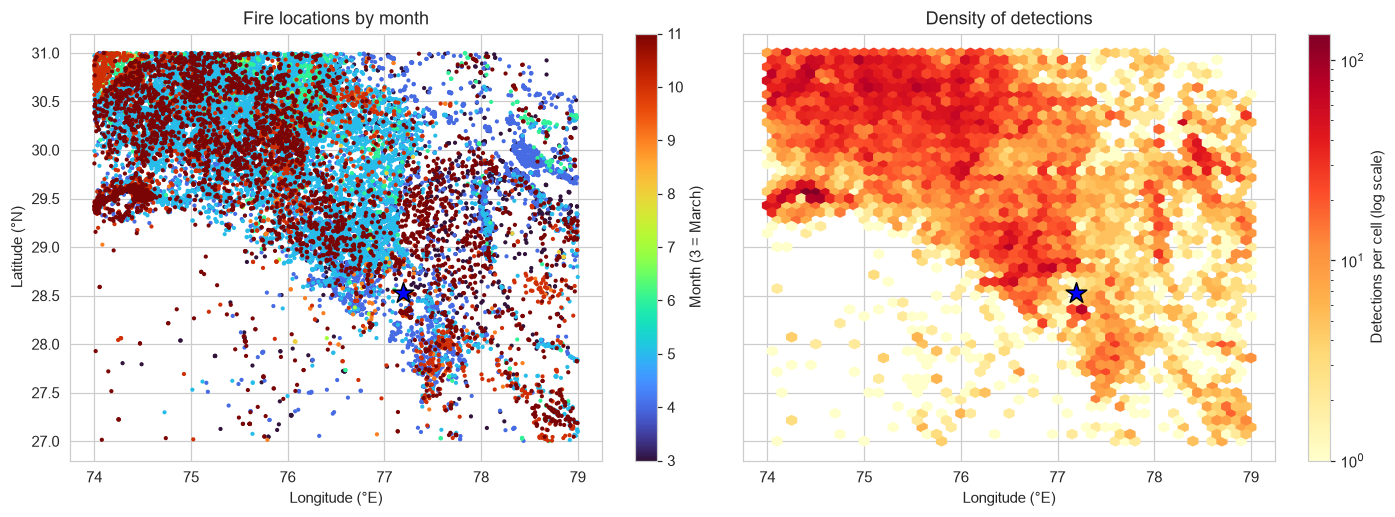

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True, sharey=True)
points = axes[0].scatter(fires["longitude"], fires["latitude"], c=fires["month"], cmap="turbo", s=3)
fig.colorbar(points, ax=axes[0], label="Month (3 = March)")
axes[0].set_title("Fire locations by month")
density = axes[1].hexbin(fires["longitude"], fires["latitude"], gridsize=50, bins="log", cmap="YlOrRd", mincnt=1)
fig.colorbar(density, ax=axes[1], label="Detections per cell (log scale)")
axes[1].set_title("Density of detections")
for ax in axes:
    ax.scatter(DELHI_LON, DELHI_LAT, marker="*", s=200, c="blue", edgecolor="k")
    ax.set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
fig.tight_layout()
plt.show()

In [12]:
fires["frp_distw"] = fires["frp"] / (fires["dist_km"] / 100)

flags = pd.DataFrame({
    "fire_near300": fires["dist_km"] < 300,
    "fire_nw": fires["region"] == "north-west",
    "fire_central": fires["region"] == "central",
    "fire_south": fires["region"] == "south",
    "fire_night": fires["daynight"] == "N",
})
totals = fires.groupby("date").agg(
    fire_count=("frp", "size"), fire_frp=("frp", "sum"), fire_frp_distw=("frp_distw", "sum"))

fires_daily = pd.concat([totals, flags.groupby(fires["date"]).sum()], axis=1).reindex(ALL_DATES, fill_value=0)

In [13]:
past = fires_daily["fire_count"].shift(1)
fires_daily["fire_count_prev3"] = past.rolling(3, min_periods=1).sum().fillna(0)
fires_daily["fire_count_prev7"] = past.rolling(7, min_periods=1).sum().fillna(0)
fires_daily["is_burning_season"] = fires_daily.index.month.isin([4, 5, 10, 11]).astype(int)

low_cut, high_cut = fires_daily["fire_count"].quantile([1 / 3, 2 / 3])
fires_daily["fire_level"] = pd.cut(fires_daily["fire_count"], [-1, low_cut, high_cut, np.inf],
                                   labels=["low", "medium", "high"])

In [14]:
(fires_daily["fire_count"] == 0).sum()

np.int64(44)

In [15]:
fires_daily.groupby("fire_level", observed=True)["fire_count"].agg(["min", "max", "count"])

,min,max,count
fire_level,,,
low,0,8,94
medium,9,53,89
high,55,1249,92


In [16]:
fires_daily.reset_index().to_csv(OUT_DIR / "fires_daily.csv", index=False)

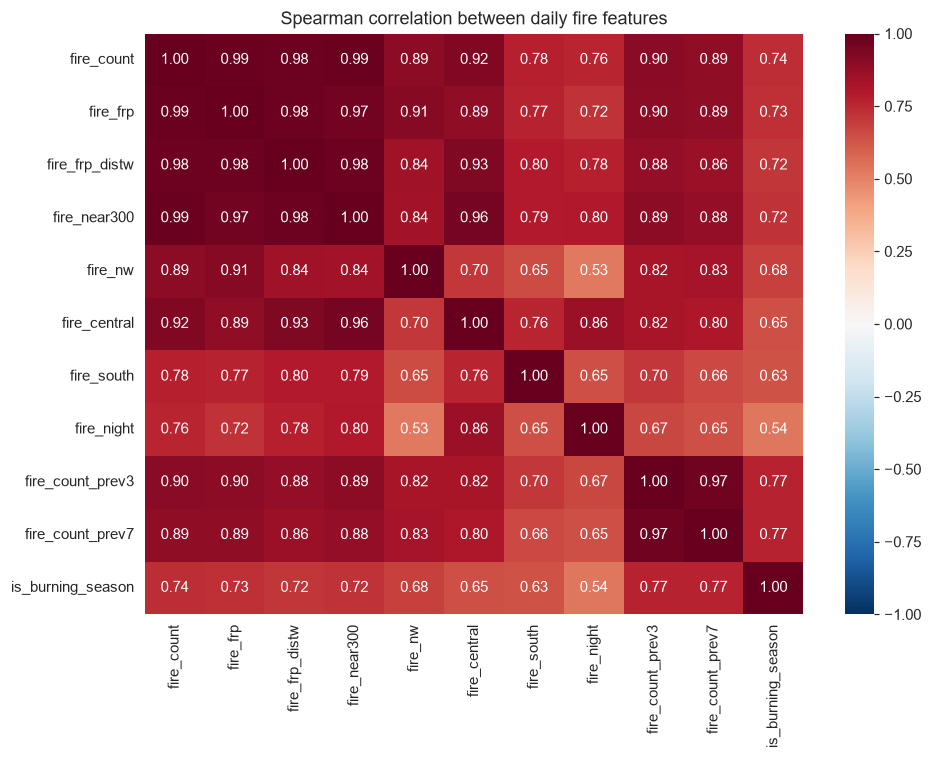

In [17]:
plt.figure(figsize=(9, 7))
sns.heatmap(fires_daily.select_dtypes("number").corr(method="spearman"),
            annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Spearman correlation between daily fire features")
plt.tight_layout()
plt.show()

In [18]:
PM_PATH = ROOT / "data/raw/air_quality/pm25_hourly_mar_nov.csv"

pm = pd.read_csv(PM_PATH)
pm["time"] = pd.to_datetime(pm["datetime_from_local"].str[:19])
pm25_daily = pm.set_index("time")["value"].resample("D").mean().reindex(ALL_DATES).rename("pm25")

lagdf = fires_daily.join(pm25_daily)
oct_nov = lagdf.index.month.isin([10, 11])
lagdf["pm25"].notna().sum(), oct_nov.sum()

(np.int64(271), np.int64(61))

In [19]:
LAGS = range(0, 6)
FEATS = ["fire_count", "fire_frp_distw", "fire_near300"]

def detrend(s, window=15):
    return s - s.rolling(window, center=True, min_periods=5).mean()

def lag_corr(x, window=None):
    y = lagdf["pm25"]
    if window:
        x, y = detrend(x, window), detrend(y, window)
    return pd.Series([y[oct_nov].corr(x.shift(k)[oct_nov], method="spearman") for k in LAGS],
                     index=pd.Index(LAGS, name="lag (days)")).round(2)

naive = pd.DataFrame({f: lag_corr(lagdf[f]) for f in FEATS})
detrended = pd.DataFrame({f: lag_corr(lagdf[f], 15) for f in FEATS})
naive

,fire_count,fire_frp_distw,fire_near300
lag (days),,,
0,0.73,0.77,0.76
1,0.70,0.75,0.72
2,0.70,0.73,0.73
3,0.68,0.72,0.71
4,0.75,0.78,0.75
5,0.79,0.79,0.78


In [20]:
detrended

,fire_count,fire_frp_distw,fire_near300
lag (days),,,
0,0.49,0.31,0.41
1,0.11,0.11,0.14
2,0.02,0.03,0.12
3,-0.13,-0.15,-0.04
4,0.07,0.11,0.05
5,-0.03,-0.03,-0.01


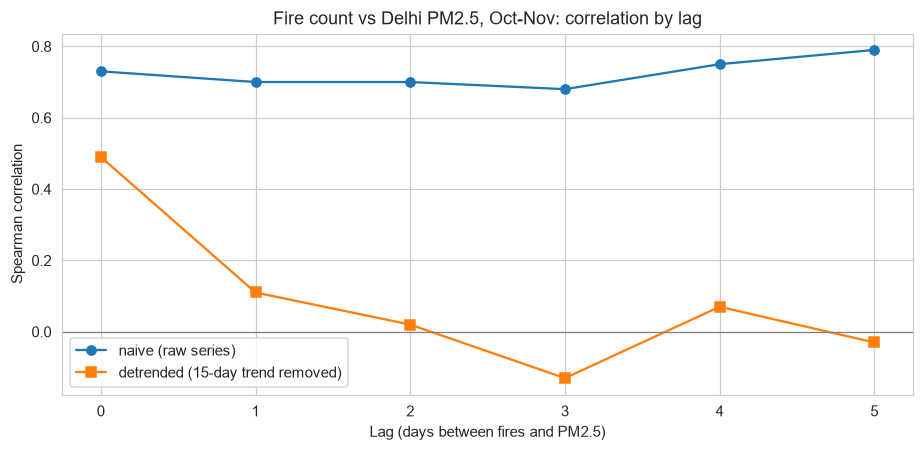

In [21]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(naive.index, naive["fire_count"], marker="o", label="naive (raw series)")
ax.plot(detrended.index, detrended["fire_count"], marker="s", label="detrended (15-day trend removed)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Fire count vs Delhi PM2.5, Oct-Nov: correlation by lag")
ax.set_xlabel("Lag (days between fires and PM2.5)")
ax.set_ylabel("Spearman correlation")
ax.legend()
fig.tight_layout()
plt.show()

In [22]:
pd.DataFrame({f"{w}-day window": lag_corr(lagdf["fire_count"], w) for w in (7, 15, 30)})

,7-day window,15-day window,30-day window
lag (days),,,
0,0.55,0.49,0.51
1,0.17,0.11,0.33
2,-0.30,0.02,0.31
3,-0.43,-0.13,0.21
4,0.04,0.07,0.37
5,0.18,-0.03,0.45


In [23]:
count_hi = fires[fires["confidence"] != "l"].groupby("date").size().reindex(ALL_DATES, fill_value=0)
pd.DataFrame({"all detections": lag_corr(lagdf["fire_count"], 15),
              "without low confidence": lag_corr(count_hi, 15)})

,all detections,without low confidence
lag (days),,
0,0.49,0.50
1,0.11,0.11
2,0.02,0.07
3,-0.13,-0.11
4,0.07,0.06
5,-0.03,-0.07


In [24]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy import stats

c = fires_daily["fire_count"]
pd.Series({"mean": c.mean(), "variance": c.var(), "variance / mean": c.var() / c.mean()}).round(1)

mean                  95.1
variance           39948.9
variance / mean      419.9
dtype: float64

In [26]:
ones = np.ones(len(c))
poisson_fit = sm.GLM(c, ones, family=sm.families.Poisson()).fit()alpha = negbin_fit.params.iloc[-1]
size = 1 / alpha
prob = size / (size + c.mean())
k = np.arange(0, c.max() + 1)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
sns.ecdfplot(c, ax=ax, label="observed days")
ax.plot(k, stats.poisson.cdf(k, c.mean()), "k--", label="Poisson fit")
ax.plot(k, stats.nbinom.cdf(k, size, prob), label="Negative binomial fit")
ax.set_xscale("symlog")
ax.set_title("Daily fire counts: observed vs fitted distributions")
ax.set_xlabel("Fire detections per day (symlog scale)")
ax.set_ylabel("Cumulative proportion of days")
ax.legend()
fig.tight_layout()
plt.show()
negbin_fit = sm.NegativeBinomial(c, ones).fit(disp=0)

pd.DataFrame({"log-likelihood": [poisson_fit.llf, negbin_fit.llf],
              "AIC": [poisson_fit.aic, negbin_fit.aic]},
             index=["Poisson", "Negative binomial"]).round(0)

SyntaxError: invalid syntax (1891133917.py, line 2)

In [27]:
adf_stat, adf_p = adfuller(c)[:2]
round(adf_stat, 2), round(adf_p, 3)

C:\Users\Mudra Shah\AppData\Local\Temp\ipykernel_26112\1713330313.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p = adfuller(c)[:2]


(-2.44, 0.13)

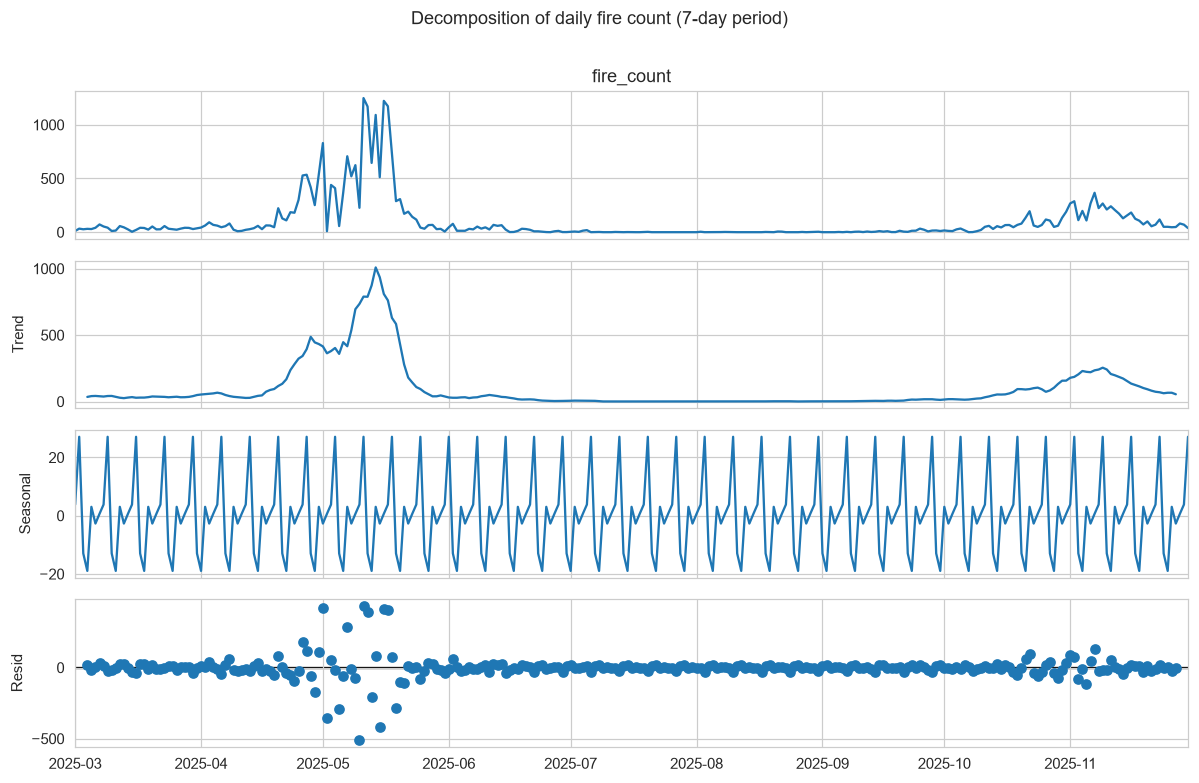

In [28]:
decomp = seasonal_decompose(c, period=7)
fig = decomp.plot()
fig.set_size_inches(11, 7)
fig.suptitle("Decomposition of daily fire count (7-day period)", y=1.01)
fig.tight_layout()
plt.show()

In [29]:
def per_100_fires(frame, months):
    d = frame.loc[frame.index.month.isin(months), ["fire_count", "pm25"]].dropna()
    return 100 * stats.linregress(d["fire_count"], d["pm25"]).slope

flat = lagdf[["fire_count", "pm25"]].apply(detrend)
effect = pd.DataFrame({
    "raw series": {"Apr-May": per_100_fires(lagdf, [4, 5]), "Oct-Nov": per_100_fires(lagdf, [10, 11])},
    "detrended (15-day)": {"Apr-May": per_100_fires(flat, [4, 5]), "Oct-Nov": per_100_fires(flat, [10, 11])},
}).round(1)
effect

,raw series,detrended (15-day)
Apr-May,0.3,-1.2
Oct-Nov,52.6,44.0
